# GraphX và GraphFrames: hiểu thí nghiệm trước khi đọc biểu đồ

Notebook này dành cho người chưa biết Spark, JVM hoặc cách đo bộ nhớ.
Chúng ta đi từ tình huống thực nghiệm, tìm hiểu chương trình chạy ở đâu, rồi đọc từng biểu đồ.
Câu hỏi chính là: **với cùng dữ liệu giao dịch và cùng phép tính, hai implementation tốn bao nhiêu thời gian, giữ bao nhiêu dữ liệu và trao đổi bao nhiêu dữ liệu khi xử lý?**

Notebook 03 thực hiện benchmark bằng Scala và lưu kết quả.
Notebook 04 đọc kết quả bằng Python để kiểm tra và trực quan hóa, không chạy lại benchmark.
Các bảng và biểu đồ dùng run được in ra ngay sau đây.

**Cách chạy:** các cell có dòng đầu `MINH HỌA SCALA` chỉ minh họa, không cần chạy và không có output.
Lệnh `python scripts/run_notebook.py notebooks/04_preprocessed_graph_results.ipynb` tự bỏ qua chúng.
Nếu dùng giao diện notebook với kernel Python, chỉ chạy các cell Python.


In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Tìm root khi mở notebook từ root hoặc từ notebooks/.
ROOT = Path.cwd()
while not (ROOT / "upstream.json").is_file():
    if ROOT == ROOT.parent:
        raise FileNotFoundError("Không tìm thấy upstream.json")
    ROOT = ROOT.parent

latest_file = ROOT / "reports/latest_preprocessed_run.json"
latest = json.loads(latest_file.read_text())
RUN = ROOT / latest["run_dir"]
assert (RUN / "SUCCESS").is_file(), "Benchmark chưa hoàn tất"

manifest = json.loads((RUN / "input_manifest.json").read_text())
schedule = pd.read_csv(RUN / "schedule.csv")
checks = pd.read_csv(RUN / "correctness.csv")
timings = pd.read_csv(RUN / "phase_timings.csv")
print("Vertices:", manifest["vertices"], "- transaction edges:", manifest["edges"])

print("Run:", RUN)
print("Upstream commit:", manifest["upstream_commit"])


Vertices: 422734 - transaction edges: 4487124
Run: /home/tuanta/BigData/graphX/reports/runs/preprocessed_1792611523334
Upstream commit: 4b74d035ab6792e6337b5236d42992c970b15081


## 1. Chúng ta đang mô phỏng tình huống nào?

Hãy tưởng tượng bạn đã có một tập giao dịch được làm sạch và muốn phân tích quan hệ giữa các tài khoản.
Mỗi tài khoản là một **vertex**, tức một đỉnh; mỗi giao dịch là một **edge**, tức một cạnh có hướng từ người gửi đến người nhận.

| Người gửi | Người nhận | Số tiền |
|---|---|---:|
| A | B | 100 USD |
| C | B | 50 USD |
| B | D | 80 USD |

Từ bảng này, ta có graph A -> B, C -> B và B -> D.
B nhận tổng cộng 150 USD, còn vị trí của B trong mạng là câu hỏi khác với số tiền B nhận.

| Công việc sẽ đo | Câu hỏi được trả lời |
|---|---|
| Cộng tiền nhận | Mỗi tài khoản nhận tổng cộng bao nhiêu USD? |
| PageRank | Tài khoản có vị trí quan trọng như thế nào theo cấu trúc liên kết và công thức đã chọn? |

HI-Small đã preprocess có 422.734 tài khoản và 4.487.124 giao dịch.
Amount đã được quy đổi sang USD; cùng một ánh xạ ID số nguyên được dùng cho cả hai framework.
Nếu A chuyển cho B nhiều lần, ta giữ từng giao dịch riêng, không dùng `edges_agg.parquet`.

**Đây là phân tích theo lô trên dữ liệu cố định đã chuẩn bị sẵn.**
Thí nghiệm chưa mô phỏng giao dịch đến liên tục, nhiều người dùng cùng truy cập hoặc cluster nhiều máy.
PageRank không tự kết luận tài khoản có rửa tiền và trong thí nghiệm này không dùng số tiền làm trọng số.

### Chương trình đang chạy ở đâu?

```text
Code Scala trong notebook 03
             |
      GraphX hoặc GraphFrames
             |
           Spark
             |
            JVM
             |
     CPU, RAM và đĩa của một máy
```

- **Scala** là ngôn ngữ viết code benchmark.
- **GraphX** xử lý graph bằng các cấu trúc dựa trên RDD, tức các tập dữ liệu chia thành nhiều phần.
- **GraphFrames** biểu diễn vertices và edges bằng DataFrame, có thể hiểu là các bảng dữ liệu.
- **Spark** chia và điều phối công việc xử lý các phần dữ liệu đó.
- **JVM**, viết tắt của Java Virtual Machine, là môi trường thực thi code Scala và Spark trong thí nghiệm.

Có thể hiểu JVM là chương trình chủ đang dùng CPU và xin bộ nhớ từ hệ điều hành để chạy công việc.
Trên cluster, Spark thường có driver điều phối và executor thực thi ở các tiến trình riêng.
Ở cấu hình local hiện tại, vai trò điều phối và thực thi nằm trên cùng máy, trong cùng JVM.
Xem [kiến trúc Spark](https://spark.apache.org/docs/3.5.7/cluster-overview.html).

Đoạn Scala dưới cho thấy cùng dữ liệu được đưa vào hai cách biểu diễn graph.
Đọc Parquet và ánh xạ ID nằm ngoài thời gian benchmark.


In [ ]:
// MINH HỌA SCALA - không cần chạy cell này.
// vertices và edges là hai bảng chung đã ánh xạ ID sang Long.
val vertexRDD = vertices.select("id").as[Long].rdd
  .map(id => (id, 1.0))
val edgeRDD = edges.select("src", "dst", "amount")
  .as[(Long, Long, Double)].rdd
  .map { case (sender, receiver, amount) => Edge(sender, receiver, amount) }
val graphX = Graph(vertexRDD, edgeRDD, 1.0)

// GraphFrames giữ representation dạng DataFrame.
val graphFrames = GraphFrame(vertices, edges)
// Bản benchmark đầy đủ còn partition và persist cả hai representation.


## 2. Trước khi so tốc độ, phải kiểm tra tính đúng

Một chương trình nhanh nhưng tính thiếu tài khoản hoặc bỏ giao dịch sẽ không tạo ra phép so sánh có ý nghĩa.
Ta tính một **reference**, tức kết quả đối chiếu độc lập, bằng vòng lặp Scala và mảng trên driver.
Mỗi tài khoản được đối chiếu với reference cho cả tổng tiền nhận và PageRank, thay vì chỉ đếm số dòng.
Một graph nhỏ kiểm tra thêm cạnh song song, tài khoản không có cạnh đi ra, không có cạnh đi vào và tài khoản cô lập.

Mỗi framework chạy 1 lượt warmup và 3 lượt đo, tổng cộng 8 lượt.
**Warmup** là lượt chạy thử để giảm ảnh hưởng của lần sử dụng đầu tiên, chẳng hạn việc tải lớp và tối ưu code của JVM.
Nó không loại bỏ hoàn toàn mọi ảnh hưởng khởi động.
Mỗi lượt có 2 kiểm tra kết quả và 5 vòng PageRank, nên có 16 kiểm tra correctness.

Reference và kiểm chứng nằm ngoài timer để không tính chi phí kiểm tra vào thời gian thuật toán.
Tuy nhiên, đối tượng tạo ra từ những bước đó vẫn có thể ảnh hưởng đến bộ nhớ JVM chung.


In [2]:
assert manifest["edge_view"] == "transactions"
assert len(schedule) == 8
assert schedule["run"].is_unique
assert set(schedule["framework"]) == {"GraphX", "GraphFrames"}
assert len(checks) == 16
assert checks["passed"].all()
assert set(checks["run"]) == set(schedule["run"])
assert set(timings["run"]) == set(schedule["run"])

expected_phases = {"build": 1, "aggregate": 1, "pr_setup": 1, "pr_iteration": 5}
for framework in ["GraphX", "GraphFrames"]:
    framework_runs = schedule[schedule["framework"] == framework]
    assert len(framework_runs) == 4
    assert framework_runs["warmup"].sum() == 1

for run_name in schedule["run"]:
    run_checks = checks[checks["run"] == run_name]
    assert len(run_checks) == 2
    assert set(run_checks["kind"]) == {"incoming", "pagerank"}
    run_timings = timings[timings["run"] == run_name]
    phase_counts = run_timings["phase"].value_counts().to_dict()
    assert phase_counts == expected_phases
print("Tất cả lượt chạy đều hợp lệ")


Tất cả lượt chạy đều hợp lệ


In [ ]:
// MINH HỌA SCALA - không cần chạy cell này.
// Trích cách kiểm chứng trong notebook benchmark.
// Các biến kết quả dưới đây là Map[Long, Double] của từng framework.
validateResult("incoming", incomingValues, expectedIncoming)
validateResult("pagerank", rankValues, expectedRanks)

// validateResult kiểm tra từng vertex, giá trị hữu hạn và:
// max(|actual - expected| / max(1, |expected|)) < 1e-9.
// Với PageRank, tổng rank còn phải lệch 1 dưới 1e-9.


In [3]:
# Bằng chứng của lần chạy thực tế được đọc từ correctness.csv.
correctness_summary = checks.groupby("kind")[["max_abs_error", "max_scaled_error"]].max()
display(correctness_summary)
print("Số kiểm tra đã đạt:", int(checks["passed"].sum()), "/", len(checks))


,max_abs_error,max_scaled_error
kind,,
incoming,7.629395e-06,3.485718e-15
pagerank,6.895526e-17,6.895526e-17


Số kiểm tra đã đạt: 16 / 16


## 3. Bài toán đầu: mỗi tài khoản nhận bao nhiêu tiền?

Với mỗi giao dịch A -> B, gửi số tiền tới B rồi cộng các khoản có cùng người nhận.
Trong ví dụ đầu notebook, A gửi B 100 USD và C gửi B 50 USD, nên B nhận 150 USD.

**Message** là giá trị được truyền dọc theo cạnh để phục vụ tính toán, không phải tin nhắn của người dùng.
Hai framework cùng gửi amount tới đích và cộng message.
Tài khoản không nhận message được xem là có tổng tiền nhận bằng 0 khi kiểm chứng.
Ta tính từ các giao dịch, không lấy cột `total_received` có sẵn để thay thế.

Phép tính một lượt này giúp quan sát chi phí truyền và cộng dữ liệu trước khi xét thuật toán lặp.


In [ ]:
// MINH HỌA SCALA - không cần chạy cell này.
// GraphX: amount nằm trong thuộc tính của cạnh, tức edge.attr.
val incomingGraphX = graphX.aggregateMessages[Double](
  sendMsg = edge => edge.sendToDst(edge.attr),
  mergeMsg = (left, right) => left + right,
  tripletFields = TripletFields.None
)

// GraphFrames: amount được truy cập theo tên cột trên cạnh.
val incomingGraphFrames = graphFrames.aggregateMessages
  .sendToDst(AggregateMessages.edge("amount"))
  .agg(sum(AggregateMessages.msg).as("incoming"))


Hai đoạn code thực hiện cùng phép tính bằng hai API khác nhau.
Phase `aggregate` bao gồm tính toán và thao tác buộc Spark tạo ra kết quả thật.
Sau khi kiểm tra kết quả tương đương, chênh lệch thời gian mới có ý nghĩa.


## 4. PageRank: khi công việc phải lặp nhiều vòng

PageRank gán điểm cho tài khoản dựa trên cấu trúc liên kết của graph.
Hình dung ban đầu mỗi tài khoản có điểm bằng nhau; mỗi vòng, nó chia điểm cho các tài khoản nhận giao dịch từ nó.
Điểm nhận được dùng để tính trạng thái vòng tiếp theo.

Hai phía khởi tạo rank bằng 1/N, dùng damping d = 0,85 và chạy đúng 5 vòng.
Damping quy định phần điểm đến từ truyền theo liên kết; công thức còn có phần điểm nền chia đều.
N là tổng số tài khoản.

$$r_{next}(v) = \frac{1-d}{N} + d\left(\sum_{u \to v}\frac{r(u)}{outDegree(u)} + \frac{danglingMass}{N}\right).$$

**Out-degree** là số giao dịch đi ra, tính cả giao dịch lặp giữa hai tài khoản.
Nếu A gửi B hai lần và C một lần, phần điểm truyền từ A chia theo tỷ lệ 2/3 tới B và 1/3 tới C.
Số tiền không tham gia vào tỷ lệ đó.
**Dangling vertex** là tài khoản không có cạnh đi ra; tổng điểm của chúng được chia đều lại cho mọi tài khoản.

Đây là cùng công thức PageRank tự triển khai qua truyền message, không phải so sánh hai hàm PageRank có sẵn.
Năm vòng tạo cùng ngân sách tính toán, chưa chứng minh điểm đã hội tụ, tức gần như không đổi giữa các vòng.


In [ ]:
// MINH HỌA SCALA - không cần chạy cell này.
// GraphX: rankGraph lưu rank ở vertex và 1 / outDegree ở cạnh.
val messages = rankGraph.aggregateMessages[Double](
  sendMsg = edge => {
    val contribution = edge.srcAttr * edge.attr
    edge.sendToDst(contribution)
  },
  mergeMsg = (left, right) => left + right,
  tripletFields = TripletFields.Src
)

// danglingMass đã được tính từ các vertex có outDegree = 0.
val teleport = (1.0 - damping) / vertexCount
val danglingShare = danglingMass / vertexCount
val nextGraph = rankGraph.outerJoinVertices(messages) { (id, oldRank, message) =>
  val incomingRank = message.getOrElse(0.0)
  teleport + damping * (incomingRank + danglingShare)
}


In [ ]:
// MINH HỌA SCALA - không cần chạy cell này.
// GraphFrames: cùng contribution nhưng viết bằng biểu thức cột.
val graph = GraphFrame(state, weightedEdges)
val contribution = AggregateMessages.src("rank") * AggregateMessages.edge("weight")
val messages = graph.aggregateMessages.sendToDst(contribution)
  .agg(sum(AggregateMessages.msg).as("message"))

// Left join giữ cả vertex không nhận message.
val receivedMessages = state.select("id", "out_degree").join(messages, Seq("id"), "left")
val incomingRank = coalesce(col("message"), lit(0.0))
val nextRank = lit(teleport) + lit(damping) * (incomingRank + lit(danglingShare))
val update = receivedMessages.select(col("id"), col("out_degree"), nextRank.as("rank"))


Hai đoạn trích cùng truyền contribution, giữ mọi tài khoản và cập nhật rank.
**Contribution** là phần điểm một tài khoản đóng góp cho tài khoản nhận.
**State** là bảng hoặc cấu trúc chứa trạng thái hiện tại, chẳng hạn điểm rank.
Notebook 03 còn tính dangling mass, lưu checkpoint và giải phóng cache trạng thái cũ mỗi vòng.
Cache và checkpoint sẽ được giải thích trước biểu đồ tài nguyên.
Xem `pageRankStep` và `frameStep` trong notebook 03 để đối chiếu implementation đầy đủ.


## 5. Đồng hồ bắt đầu và kết thúc ở đâu?

**Phase** là một công đoạn được đo riêng.
Spark thực thi lazy: viết biểu thức thường mới mô tả công việc, chưa tính toàn bộ dữ liệu ngay.
**Action**, chẳng hạn `count()`, yêu cầu Spark thực hiện công việc để trả kết quả.
**Materialize** nghĩa là thực sự tính ra dữ liệu, thay vì mới mô tả cách tính.
Timer phải chờ các action hoàn tất để đo công việc thật.

| Phase | Việc trong timer | Cách hiểu |
|---|---|---|
| `build` | Tạo representation, partition và materialize | Dựng và lưu cấu trúc graph |
| `aggregate` | Gửi amount, cộng và materialize | Tính tổng tiền nhận |
| `pr_setup` | Degree, trọng số, rank ban đầu và checkpoint | Chuẩn bị thuật toán lặp |
| `pr_iteration` | Dangling reduction, message, cập nhật, checkpoint và dọn state cũ | Một vòng PageRank hoàn chỉnh |

**Representation** là cách framework tổ chức dữ liệu graph trong các cấu trúc của nó.
`pr_total` là setup cộng 5 vòng PageRank.
`total` là tổng các phase đã đo trong một lượt.
Preprocessing, đọc input, ánh xạ ID, reference và kiểm chứng đều nằm ngoài tổng này.

Phép đo gần với tình huống **dữ liệu đã sẵn sàng và người phân tích bắt đầu dựng graph để tính toán**.
Nó chưa đo toàn bộ thời gian từ giao dịch thô tới báo cáo cuối cùng.


In [ ]:
// MINH HỌA SCALA - không cần chạy cell này.
// Ví dụ ranh giới timer thật trong runGraphX của notebook 03.
startPhase("aggregate")
val incoming = incomingAmounts(graph).persist(storageLevel)
incoming.count()
incoming.values.sum()
finishPhase()

// Thu kết quả và đối chiếu correctness sau khi timer đã kết thúc.
val incomingValues = incoming.collect().toMap
validateResult("incoming", incomingValues, expectedIncoming)


### Một máy, hai luồng thực thi, bốn phần dữ liệu

**Partition** là một phần dữ liệu; **task** là đơn vị công việc Spark thực hiện trên một partition ở một bước xử lý.
Nếu một bước có 4 task và chạy được 2 task đồng thời, chúng được thực hiện theo các đợt.
Một thuật toán nhiều bước có thể tạo nhiều task hơn số partition.

| Điều kiện | Thiết lập | Ý nghĩa |
|---|---|---|
| Máy thực thi | Một máy, `local[2]` | 2 luồng thực hiện task đồng thời, không phải 2 máy |
| Chia dữ liệu | 4 partitions ở các bước đã cấu hình | Chia việc thành các phần; không bảo đảm chi phí từng phần bằng nhau |
| Heap JVM | Tối đa 6 GB | Giới hạn vùng heap, không phải toàn bộ RAM tiến trình |
| Lưu dữ liệu | `MEMORY_AND_DISK` | Giữ trong RAM khi có thể; phần không lưu được trong RAM có thể lưu trên đĩa |
| Workload | Cùng input, d = 0,85, 5 vòng PageRank | Cùng phép tính |
| Lặp | 1 warmup + 3 lượt đo mỗi framework | Quan sát biến động sau lượt chạy thử |
| Thứ tự | Trộn bằng seed 42, chạy lần lượt | Giảm thiên lệch thứ tự; không chạy hai framework cùng lúc |

Mỗi lượt dựng graph mới và dọn cache riêng; cache input chung được giữ lại.
Hai framework vẫn dùng chung JVM, nên dọn cache không đưa toàn bộ tiến trình về trạng thái mới khởi động.

GraphX dùng EdgePartition2D; GraphFrames phân phối lại edges theo người gửi `src`.
Đây là hai chiến lược chia graph của cấu hình đang so sánh.
GraphFrames tắt AQE, tức tối ưu kế hoạch thích nghi khi chạy, và broadcast join, tức gửi bản sao bảng nhỏ tới nơi xử lý.
Kết quả gắn với những lựa chọn này, chưa đại diện cho cấu hình tối ưu nhất của từng framework.
Checkpoint I/O nằm trong timer ở cả hai bên.


In [4]:
records = []
for entry in schedule.itertuples(index=False):
    if entry.warmup:
        continue

    run_timings = timings[timings["run"] == entry.run]
    phase_times = run_timings.groupby("phase")["wall_ms"].sum().to_dict()
    phase_times["pr_total"] = phase_times["pr_setup"] + phase_times["pr_iteration"]
    phase_times["total"] = (
        phase_times["build"] + phase_times["aggregate"] + phase_times["pr_total"]
    )
    for phase, elapsed in phase_times.items():
        records.append({
            "run": entry.run,
            "framework": entry.framework,
            "repeat": entry.repeat,
            "phase": phase,
            "wall_ms": elapsed,
        })
results = pd.DataFrame(records)
analysis_dir = RUN / "analysis"
analysis_dir.mkdir(exist_ok=True)
results.to_csv(analysis_dir / "per_run_timings.csv", index=False)


### Vì sao dùng median, min và max?

Với ba thời gian 1,0 giây, 1,1 giây và 1,8 giây, **median** là số ở giữa: 1,1 giây.
**Min** là lượt nhanh nhất và **max** là lượt chậm nhất.
Chúng mô tả kết quả điển hình và phạm vi dao động của ba lượt đo sau khi loại warmup.
Ba lượt vẫn là mẫu nhỏ; min/max không phải khoảng tin cậy thống kê.


In [5]:
phase_order = ["build", "aggregate", "pr_setup", "pr_iteration", "pr_total", "total"]
frameworks = ["GraphX", "GraphFrames"]
summary_rows = []
for phase in phase_order:
    for framework in frameworks:
        phase_results = results[results["phase"] == phase]
        framework_results = phase_results[phase_results["framework"] == framework]
        elapsed = framework_results["wall_ms"]
        summary_rows.append({
            "phase": phase,
            "framework": framework,
            "median": elapsed.median(),
            "minimum": elapsed.min(),
            "maximum": elapsed.max(),
        })
summary = pd.DataFrame(summary_rows)
display(summary.round(2))
summary.to_csv(analysis_dir / "timings.csv", index=False)


,phase,framework,median,minimum,maximum
0,build,GraphX,5792.20,5564.39,6065.74
1,build,GraphFrames,1493.24,1481.46,1494.06
2,aggregate,GraphX,133.56,124.17,136.71
3,aggregate,GraphFrames,2168.39,2085.44,2228.19
4,pr_setup,GraphX,447.50,314.79,507.24
5,pr_setup,GraphFrames,5464.24,5452.20,5494.04
6,pr_iteration,GraphX,1388.04,1339.43,1496.84
7,pr_iteration,GraphFrames,23458.50,21122.91,23528.28
8,pr_total,GraphX,1835.54,1811.62,1846.68
9,pr_total,GraphFrames,28952.53,26575.11,28992.52


## 6. Biểu đồ thời gian: nhanh hơn ở công đoạn nào?

Trục ngang là công đoạn; trục dọc là giây, cột thấp hơn nghĩa là nhanh hơn.
Cột là median của ba lượt; thanh sai số đi từ min tới max.

1. **Build:** ai dựng graph nhanh hơn khi input sẵn sàng?
2. **Aggregate:** ai tính một lượt truyền và cộng message nhanh hơn?
3. **PR total:** ai hoàn thành setup và 5 vòng PageRank nhanh hơn?
4. **Total:** tổng chi phí workload đã định nghĩa là bao nhiêu?

Đừng cộng cả bốn nhóm: `total` đã bao gồm build, aggregate và pr_total.
Trong bảng, `pr_iteration` là tổng 5 vòng mỗi lượt, không phải một vòng.
Biểu đồ cho thấy lợi thế ở bước chuẩn bị có còn giữ được khi thực hiện thuật toán hay không.


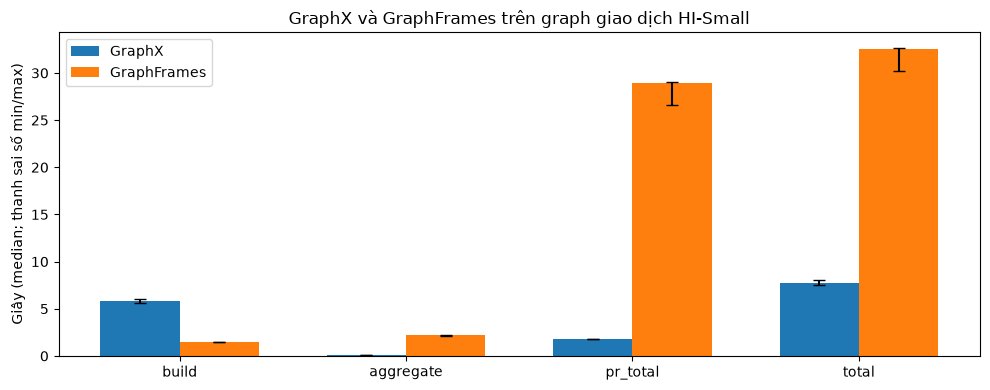

In [6]:
plot_phases = ["build", "aggregate", "pr_total", "total"]
positions = list(range(len(plot_phases)))
bar_width = 0.35
figure, axis = plt.subplots(figsize=(10, 4))

for framework_index, framework in enumerate(frameworks):
    framework_summary = summary[summary["framework"] == framework]
    framework_summary = framework_summary.set_index("phase")
    values = []
    errors_below = []
    errors_above = []
    bar_positions = []
    offset = (framework_index - 0.5) * bar_width
    for position, phase in enumerate(plot_phases):
        statistics = framework_summary.loc[phase]
        median_seconds = statistics["median"] / 1000
        values.append(median_seconds)
        errors_below.append((statistics["median"] - statistics["minimum"]) / 1000)
        errors_above.append((statistics["maximum"] - statistics["median"]) / 1000)
        bar_positions.append(position + offset)
    axis.bar(bar_positions, values, width=bar_width, label=framework,
             yerr=[errors_below, errors_above], capsize=4)

axis.set_xticks(positions, plot_phases)
axis.set_ylabel("Giây (median; thanh sai số min/max)")
axis.set_title("GraphX và GraphFrames trên graph giao dịch HI-Small")
axis.legend()
figure.tight_layout()
figure.savefig(analysis_dir / "timings.png", dpi=160)
plt.show()


### Đọc tỷ lệ thời gian

Tỷ lệ là median GraphFrames chia cho median GraphX.
Tỷ lệ 4 nghĩa là GraphFrames mất thời gian gấp 4 lần GraphX; tỷ lệ 0,25 nghĩa là chỉ mất một phần tư.
Giá trị 1 nghĩa là hai median bằng nhau.
Bảng dùng số của lần chạy hiện tại.


In [7]:
ratios = summary.pivot(index="phase", columns="framework", values="median")
ratios["GraphFrames / GraphX"] = ratios["GraphFrames"] / ratios["GraphX"]
display(ratios[["GraphFrames / GraphX"]].round(3))
ratios.to_csv(analysis_dir / "ratios.csv")


framework,GraphFrames / GraphX
phase,
aggregate,16.235
build,0.258
pr_iteration,16.900
pr_setup,12.211
pr_total,15.773
total,4.187


## 7. Bộ nhớ: chương trình giữ những gì và giữ ở đâu?

Thời gian cho biết phải chờ bao lâu.
Chỉ số tài nguyên cho biết lượng dữ liệu giữ lại và công việc trao đổi đi kèm.
Các bảng này cũng dùng ba lượt đo, loại warmup.

### Cache và Spark block là gì?

Nếu dùng một tập giao dịch nhiều lần, đọc và tính lại từ đầu sẽ lặp công việc.
**Cache** là giữ dữ liệu đã tính để dùng lại.
Có thể ví file trên đĩa là tài liệu trong tủ, cache trong RAM là tài liệu để sẵn trên bàn.
RAM là bộ nhớ làm việc; đĩa lưu file và thường chậm hơn khi truy cập.

Spark quản lý dữ liệu lưu trữ thành các đơn vị gọi là **block**.
Với cache ở đây, một block thường chứa dữ liệu của một partition đã tính.
Thuật toán tạo nhiều tập dữ liệu sẽ có nhiều block, nên 4 partitions không có nghĩa toàn chương trình chỉ có 4 block.

```text
Một tập dữ liệu được chia thành các partition
    Partition 0 -> block được cache
    Partition 1 -> block được cache
    Partition 2 -> block được cache
    Partition 3 -> block được cache
```

`persist(MEMORY_AND_DISK)` yêu cầu giữ dữ liệu; action mới buộc dữ liệu được tính và lưu.
**Cache workload cuối phase** là tổng dung lượng block cache trong RAM cuối phase trừ cache input chung đầu lượt.
Nó cho biết implementation còn giữ bao nhiêu dữ liệu Spark để dùng tiếp.
Dữ liệu tạm đã giải phóng trước cuối phase không được tính, nên đây không phải peak RAM.
Xem [Spark persistence](https://spark.apache.org/docs/3.5.7/rdd-programming-guide.html#rdd-persistence).

### Heap và RSS nhìn bộ nhớ ở phạm vi khác

| Chỉ số | Cách hiểu | Không được suy ra |
|---|---|---|
| Cache workload cuối phase | Dữ liệu Spark còn giữ trong RAM để dùng tiếp | Toàn bộ RAM cần cho thuật toán |
| Heap đang dùng | Vùng nhớ JVM dùng cho đối tượng: cache, biến, dữ liệu tạm và các cấu trúc khác | Chỉ riêng dữ liệu graph |
| RSS | Bộ nhớ tiến trình JVM hiện diện trong RAM vật lý, gồm phần trong và ngoài heap | RAM toàn máy hoặc RAM của riêng framework |

**Không cộng cache + heap + RSS: chúng có phần nằm trong nhau, không phải ba khoản độc lập.**
Heap có thể chứa đối tượng không còn cần nhưng chưa được thu hồi.
RSS còn chứa bộ nhớ ngoài heap, chẳng hạn một số buffer và cấu trúc JVM; không gồm page cache toàn hệ điều hành.

Notebook lấy mẫu heap/RSS mỗi 100 mili giây và ở hai đầu phase, rồi lấy mức cao nhất quan sát được.
Đỉnh rất ngắn giữa hai mẫu có thể bị bỏ sót.
Bảng giữ cả baseline, tức mức đầu phase, để cung cấp bối cảnh.
Hai framework dùng chung JVM và input, không ép thu gom rác giữa các lượt, nên heap/RSS không tách riêng RAM từng thư viện.
Lấy mẫu cũng tạo thêm một ít công việc trong khi benchmark chạy.

### Checkpoint, spill và GC khác nhau thế nào?

| Khái niệm | Hình dung | Mục đích hoặc nguyên nhân |
|---|---|---|
| Checkpoint | Chủ động lưu bản kết quả trung gian | Giữ trạng thái và cắt chuỗi phụ thuộc tính toán trước đó |
| Spill | Đang làm việc phải đưa dữ liệu trung gian ra đĩa | Cấu trúc xử lý không tiếp tục giữ hết trong bộ nhớ được cấp |
| GC: Garbage Collection | Dọn đối tượng không còn cần | JVM thu hồi bộ nhớ để tái sử dụng |

Hai phía checkpoint trạng thái PageRank mỗi vòng; chi phí nằm trong timer.
Spill khác checkpoint và khác đưa cache xuống đĩa theo storage level.
Không có spill không có nghĩa không ghi đĩa: shuffle và checkpoint vẫn có thể ghi.
Dọn cache không bảo đảm RSS giảm ngay, vì JVM có thể giữ vùng nhớ để tái sử dụng.

**Max task execution memory** là peak lớn nhất của một task theo các cấu trúc thực thi Spark theo dõi, không phải toàn bộ RAM của task hay JVM.
Giá trị 0 không có nghĩa không dùng RAM, đặc biệt với RDD operators của GraphX.
GC time là mức tăng thời gian thu gom rác JVM trong phase; không cộng GC time từng task để tránh đếm trùng.
Xem [định nghĩa task metrics của Spark](https://spark.apache.org/docs/3.5.7/monitoring.html#executor-task-metrics).


In [8]:
task_metrics = pd.read_csv(RUN / "phase_task_metrics.csv")
keys = ["run", "phase", "iteration"]
assert not task_metrics.duplicated(keys).any()
assert len(task_metrics) == len(timings)
resources = timings.merge(task_metrics, on=keys, validate="one_to_one")
resources = resources.merge(schedule, on="run", validate="many_to_one")
resources = resources[~resources["warmup"]].copy()
assert (resources["tasks"] > 0).all()
assert (resources["failed_tasks"] == 0).all()
assert (resources["memory_samples"] >= 2).all()
assert (resources["heap_sampled_peak_bytes"] >= resources["heap_start_bytes"]).all()
assert (resources["rss_sampled_peak_bytes"] >= resources["rss_start_bytes"]).all()
assert (resources["workload_cache_end_bytes"] >= 0).all()
resources.to_csv(analysis_dir / "phase_resources.csv", index=False)
print("Đã ghép đầy đủ", len(resources), "phase của các lượt đo.")


Đã ghép đầy đủ

 48 phase của các lượt đo.


### Cách đọc ba biểu đồ bộ nhớ

Trục dọc tính bằng MiB; 1 MiB = 1.048.576 byte.
Trục ngang là phase; cột là median và thanh sai số là min/max của ba lượt.
Với `pr_iteration`, lấy giá trị lớn nhất qua 5 vòng trong mỗi lượt rồi mới tính thống kê giữa các lượt.
Không cộng peak giữa các vòng hoặc các phase.

1. **Cache workload cuối phase:** implementation giữ bao nhiêu dữ liệu Spark để dùng tiếp?
2. **Heap peak lấy mẫu:** heap của JVM chung đã dùng cao tới đâu trong các mẫu?
3. **RSS peak lấy mẫu:** tiến trình JVM chung hiện diện trong RAM vật lý cao tới đâu?

Cache có thể phản ánh graph, trạng thái thuật toán và cấu trúc còn giữ từ bước trước.
GraphX giữ một số cấu trúc chuẩn bị PageRank tới cleanup; GraphFrames có vòng đời state/messages riêng.
Chênh lệch này mô tả implementation hiện tại, không chứng minh lượng RAM tối thiểu mỗi thư viện bắt buộc cần.
Cache cuối phase bỏ qua message hoặc dữ liệu trung gian đã giải phóng trước khi đo.


MiB                       workload_cache_end_bytes  heap_start_bytes  \
phase        framework                                                 
aggregate    GraphFrames                    105.37            948.87   
             GraphX                         298.02           2487.83   
build        GraphFrames                    109.36           2177.26   
             GraphX                         276.24           1604.92   
pr_iteration GraphFrames                    158.16           2308.47   
             GraphX                         555.68           2896.04   
pr_setup     GraphFrames                    158.16           2466.76   
             GraphX                         555.68           3151.83   

MiB                       heap_sampled_peak_bytes  rss_start_bytes  \
phase        framework                                               
aggregate    GraphFrames                  2452.30          4049.82   
             GraphX                       2979.83          4793.83   
build        GraphFrames                  2505.51          4048.78   
             GraphX                       3220.93          4216.28   
pr_iteration GraphFrames                  2642.22          4213.96   
             GraphX                       3540.04          5456.57   
pr_setup     GraphFrames                  2696.30          4076.47   
             GraphX                       3151.83          4793.88   

MiB                       rss_sampled_peak_bytes  cache_disk_end_bytes  \
phase        framework                                                   
aggregate    GraphFrames                 4069.32                   0.0   
             GraphX                      4793.90                   0.0   
build        GraphFrames                 4049.71                   0.0   
             GraphX                      5990.89                   0.0   
pr_iteration GraphFrames                 4216.30                   0.0   
             GraphX                      5460.16                   0.0   
pr_setup     GraphFrames                 4193.22                   0.0   
             GraphX                      5035.14                   0.0   

MiB                       max_task_execution_memory_bytes  
phase        framework                                     
aggregate    GraphFrames                           524.25  
             GraphX                                  0.00  
build        GraphFrames                             0.00  
             GraphX                                  0.00  
pr_iteration GraphFrames                           328.25  
             GraphX                                  0.00  
pr_setup     GraphFrames                           328.50  
             GraphX                                  0.00

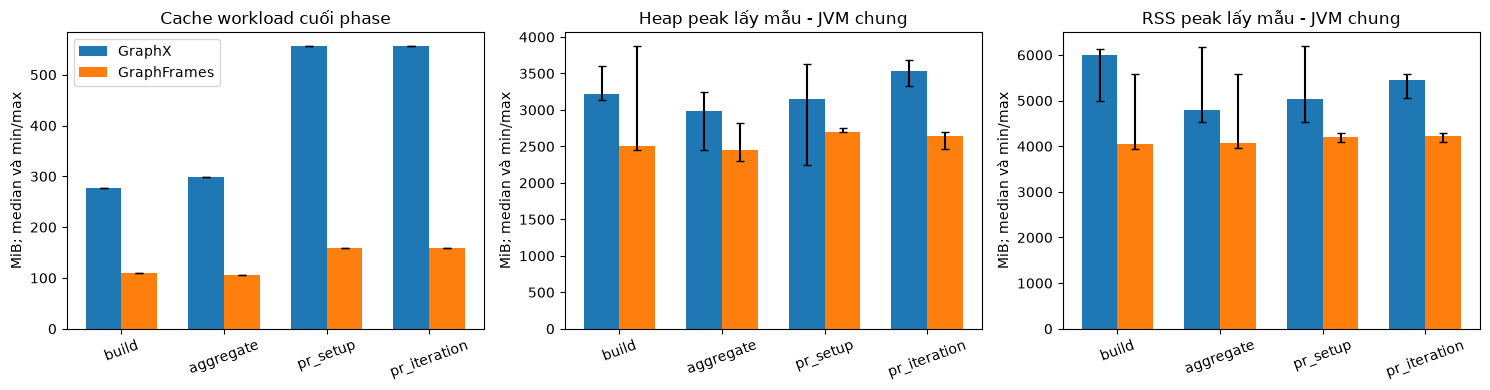

In [9]:
memory_columns = [
    "workload_cache_end_bytes", "heap_start_bytes", "heap_sampled_peak_bytes",
    "rss_start_bytes", "rss_sampled_peak_bytes", "cache_disk_end_bytes",
    "max_task_execution_memory_bytes",
]
memory_per_run = resources.groupby(["run", "framework", "phase"])[memory_columns].max().reset_index()
memory_summary = memory_per_run.groupby(["phase", "framework"])[memory_columns].median()
display((memory_summary / 1024**2).round(2).rename_axis(columns="MiB"))
memory_per_run.to_csv(analysis_dir / "memory_per_run.csv", index=False)
memory_summary.to_csv(analysis_dir / "memory_median_bytes.csv")

resource_phases = ["build", "aggregate", "pr_setup", "pr_iteration"]
figure, axes = plt.subplots(1, 3, figsize=(15, 4))
plot_columns = ["workload_cache_end_bytes", "heap_sampled_peak_bytes", "rss_sampled_peak_bytes"]
plot_titles = ["Cache workload cuối phase", "Heap peak lấy mẫu - JVM chung", "RSS peak lấy mẫu - JVM chung"]
for axis, column, title in zip(axes, plot_columns, plot_titles):
    for framework_index, framework in enumerate(frameworks):
        values = []
        low = []
        high = []
        positions = []
        for phase_index, phase in enumerate(resource_phases):
            selected = memory_per_run[(memory_per_run["framework"] == framework) & (memory_per_run["phase"] == phase)]
            data = selected[column] / 1024**2
            median = data.median()
            values.append(median)
            low.append(median - data.min())
            high.append(data.max() - median)
            positions.append(phase_index + (framework_index - 0.5) * 0.35)
        axis.bar(positions, values, width=0.35, yerr=[low, high], capsize=3, label=framework)
    axis.set_xticks(range(4), resource_phases, rotation=20)
    axis.set_ylabel("MiB; median và min/max")
    axis.set_title(title)
axes[0].legend()
figure.tight_layout()
figure.savefig(analysis_dir / "memory.png", dpi=160)
plt.show()


### Shuffle: cùng người nhận thì dữ liệu phải được đưa về đâu?

Giả sử partition 0 có A -> B: 100 USD, partition 1 có C -> B: 50 USD.
Muốn cộng cho B, các khoản đóng góp cùng khóa B phải được đưa tới nơi có thể tổng hợp.
Phân phối lại dữ liệu giữa các partition như vậy gọi là **shuffle**.
Nó phát sinh công việc tổ chức, ghi và đọc dữ liệu.

- **Shuffle write:** số byte ghi ra phục vụ trao đổi.
- **Shuffle read:** số byte đọc vào từ trao đổi, gồm local và remote.

Ở local mode, trao đổi diễn ra trên một máy, nên shuffle không đồng nghĩa traffic mạng giữa các máy.
Xem [Spark shuffle](https://spark.apache.org/docs/3.5.7/rdd-programming-guide.html#shuffle-operations).

Hai biểu đồ so lượng đọc và ghi bằng MiB.
Cột dùng median của tổng byte theo phase trong mỗi lượt; `pr_iteration` là tổng 5 vòng.
Task được tính khi thực sự chạy, không đếm lại stage chỉ vì nhiều job tham chiếu nó.
Job là yêu cầu tính toán do action tạo ra; stage là nhóm task trong kế hoạch thực thi job.
Job ngoài timer như reference, correctness và chẩn đoán partition bị loại.

Shuffle lớn hơn đi kèm thời gian dài hơn là bằng chứng về chi phí trao đổi, chưa chứng minh nguyên nhân duy nhất gây chậm.
Shuffle ít vẫn có thể chậm do CPU, số bước, checkpoint và các công việc khác.
Bảng spill/GC cung cấp thêm bối cảnh; memory spill và disk spill khác biểu diễn, không cộng thành một dung lượng.
Nếu spill bằng 0, workload chưa bộc lộ áp lực spill; chưa biết bên nào ứng xử tốt hơn khi thiếu bộ nhớ.


shuffle_read_bytes  shuffle_write_bytes  \
phase        framework                                              
aggregate    GraphFrames          39939224.0           39939224.0   
             GraphX                5276600.0            5276600.0   
build        GraphFrames          83095931.0           83095931.0   
             GraphX               53833546.0           53833546.0   
pr_iteration GraphFrames         207130941.0          138088474.0   
             GraphX               66614595.0           38727572.0   
pr_setup     GraphFrames           2201022.0            2201022.0   
             GraphX                5180002.0            5180002.0   

                          memory_spill_bytes  disk_spill_bytes  tasks  \
phase        framework                                                  
aggregate    GraphFrames                 0.0               0.0   19.0   
             GraphX                      0.0               0.0    8.0   
build        GraphFrames                 0.0               0.0   14.0   
             GraphX                      0.0               0.0   16.0   
pr_iteration GraphFrames                 0.0               0.0  135.0   
             GraphX                      0.0               0.0   60.0   
pr_setup     GraphFrames                 0.0               0.0   20.0   
             GraphX                      0.0               0.0   22.0   

                          jvm_gc_ms  
phase        framework               
aggregate    GraphFrames       11.0  
             GraphX             0.0  
build        GraphFrames       32.0  
             GraphX           566.0  
pr_iteration GraphFrames      100.0  
             GraphX            14.0  
pr_setup     GraphFrames       46.0  
             GraphX            15.0

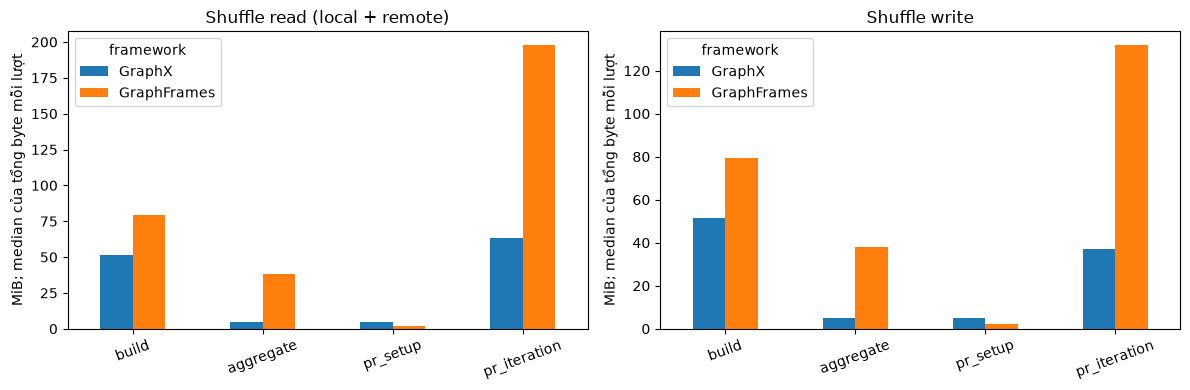

,memory_spill_bytes,disk_spill_bytes
framework,,
GraphFrames,0,0
GraphX,0,0


Không ghi nhận spill trong các phase đo: workload này chưa bộc lộ áp lực spill.
Task peak execution memory = 0 không đồng nghĩa với không dùng RAM, đặc biệt với RDD operators.


In [10]:
sum_columns = ["shuffle_read_bytes", "shuffle_write_bytes", "memory_spill_bytes", "disk_spill_bytes", "tasks", "jvm_gc_ms"]
traffic_per_run = resources.groupby(["run", "framework", "phase"])[sum_columns].sum().reset_index()
traffic_summary = traffic_per_run.groupby(["phase", "framework"])[sum_columns].median()
display(traffic_summary.round(2))
traffic_summary.to_csv(analysis_dir / "traffic_spill_gc_median.csv")
figure, axes = plt.subplots(1, 2, figsize=(12, 4))
for axis, column, title in zip(axes, ["shuffle_read_bytes", "shuffle_write_bytes"], ["Shuffle read (local + remote)", "Shuffle write"]):
    data = traffic_summary[column].unstack("framework").reindex(resource_phases)
    (data[frameworks] / 1024**2).plot.bar(ax=axis, rot=20)
    axis.set_title(title)
    axis.set_ylabel("MiB; median của tổng byte mỗi lượt")
    axis.set_xlabel("")
figure.tight_layout()
figure.savefig(analysis_dir / "shuffle.png", dpi=160)
plt.show()

spill_totals = resources.groupby("framework")[["memory_spill_bytes", "disk_spill_bytes"]].sum()
display(spill_totals)
if spill_totals.to_numpy().sum() == 0:
    print("Không ghi nhận spill trong các phase đo: workload này chưa bộc lộ áp lực spill.")
print("Task peak execution memory = 0 không đồng nghĩa với không dùng RAM, đặc biệt với RDD operators.")


### Mỗi vòng PageRank có giống nhau không?

Biểu đồ trái đo thời gian, bên phải đo shuffle read; trục ngang là vòng 1 tới 5.
Đường là median ba lượt tại cùng vòng; dải màu là min/max.
Thời gian gồm tính dangling mass, truyền message, cập nhật, checkpoint và dọn state cũ.

Đọc ba điều: ai nhanh hơn từng vòng, chi phí có đổi qua vòng không và thời gian có thay đổi cùng chiều với shuffle không.
Tổng thời gian có thể che khuất biến động, nên cần cả hai đồ thị.
Nếu shuffle tăng dần, không tự kết luận thiếu RAM hay rò rỉ bộ nhớ; cần xem DAG hoặc execution plan, tức sơ đồ các bước Spark thực hiện.
Năm vòng đo chi phí lặp cố định, không chứng minh PageRank hội tụ.


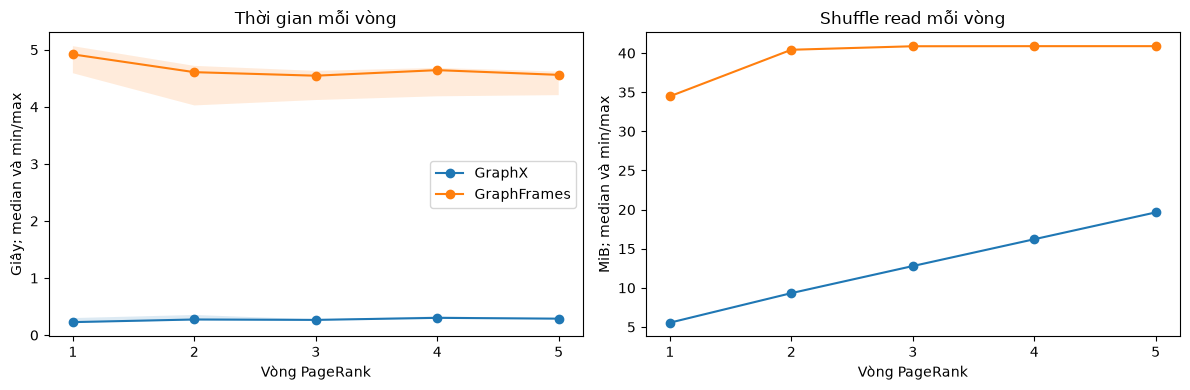

In [11]:
iteration_resources = resources[resources["phase"] == "pr_iteration"]
figure, axes = plt.subplots(1, 2, figsize=(12, 4))
for framework in frameworks:
    selected = iteration_resources[iteration_resources["framework"] == framework]
    for axis, column, divisor, ylabel in [
        (axes[0], "wall_ms", 1000, "Giây; median và min/max"),
        (axes[1], "shuffle_read_bytes", 1024**2, "MiB; median và min/max"),
    ]:
        statistics = selected.groupby("iteration")[column].agg(["median", "min", "max"]) / divisor
        axis.plot(statistics.index, statistics["median"], marker="o", label=framework)
        axis.fill_between(statistics.index, statistics["min"], statistics["max"], alpha=0.15)
        axis.set_xlabel("Vòng PageRank")
        axis.set_xticks([1, 2, 3, 4, 5])
        axis.set_ylabel(ylabel)
axes[0].set_title("Thời gian mỗi vòng")
axes[1].set_title("Shuffle read mỗi vòng")
axes[0].legend()
figure.tight_layout()
figure.savefig(analysis_dir / "pagerank_iterations.png", dpi=160)
plt.show()


### Ghép các biểu đồ thành câu chuyện có bằng chứng

Bảng kế tiếp đặt thời gian, cache, shuffle, spill và GC của cùng run cạnh nhau.

| Câu hỏi | Bằng chứng |
|---|---|
| Phải chờ bao lâu? | Thời gian theo phase và từng vòng |
| Implementation giữ gì để dùng tiếp? | Cache workload cuối phase |
| JVM chung dùng bộ nhớ thế nào? | Heap/RSS, baseline và bối cảnh GC |
| Bao nhiêu dữ liệu phải phân phối lại? | Shuffle read/write |
| Có áp lực đưa dữ liệu xử lý ra đĩa không? | Spill trong các task đo được |

Trong kết quả đang trình bày, GraphFrames dựng graph nhanh hơn, còn GraphX nhanh hơn ở cộng message và PageRank.
GraphX đồng thời giữ cache PageRank lớn hơn và có shuffle thấp hơn ở các vòng lặp.
Đây là đặc điểm quan sát cùng lúc, chưa chứng minh tăng cache sẽ giảm shuffle hay thời gian.

Đối chiếu `pr_setup`: shuffle ít hơn vẫn có thể đi cùng thời gian dài hơn vì còn checkpoint và các công việc khác.
Đường theo vòng cho thấy chi phí thay đổi trong quá trình lặp; muốn giải thích nguyên nhân cần xem thêm kế hoạch thực thi.
Không kết luận ai cần ít RAM hơn chỉ từ heap/RSS của JVM chung.
Các số bên dưới lấy từ kết quả hiện tại để không lẫn lần chạy cũ.


In [12]:
evidence = traffic_summary.copy()
evidence["wall_ms"] = resources.groupby(["run", "framework", "phase"])["wall_ms"].sum().groupby(["phase", "framework"]).median()
evidence["cache_end_MiB"] = memory_summary["workload_cache_end_bytes"] / 1024**2
evidence["heap_peak_MiB_shared_JVM"] = memory_summary["heap_sampled_peak_bytes"] / 1024**2
evidence["rss_peak_MiB_shared_JVM"] = memory_summary["rss_sampled_peak_bytes"] / 1024**2
evidence["shuffle_read_MiB"] = evidence.pop("shuffle_read_bytes") / 1024**2
evidence["shuffle_write_MiB"] = evidence.pop("shuffle_write_bytes") / 1024**2
display(evidence.round(2))
evidence.to_csv(analysis_dir / "evidence_summary.csv")
print("Tỷ lệ tổng thời gian GraphFrames / GraphX:", round(ratios.loc["total", "GraphFrames / GraphX"], 2))

for phase in ["build", "aggregate", "pr_iteration"]:
    gx = evidence.loc[(phase, "GraphX")]
    gf = evidence.loc[(phase, "GraphFrames")]
    print(phase, "- GraphX / GraphFrames:")
    print("  Thời gian (giây):", round(gx["wall_ms"] / 1000, 2), "/", round(gf["wall_ms"] / 1000, 2))
    print("  Cache cuối phase (MiB):", round(gx["cache_end_MiB"], 1), "/", round(gf["cache_end_MiB"], 1))
    print("  Shuffle read (MiB):", round(gx["shuffle_read_MiB"], 1), "/", round(gf["shuffle_read_MiB"], 1))
print("pr_iteration: thời gian và shuffle là tổng 5 vòng; cache là giá trị cuối phase lớn nhất qua 5 vòng.")
print("Kết luận memory giới hạn ở footprint cache; heap/RSS là quan sát JVM chung.")


memory_spill_bytes  disk_spill_bytes  tasks  \
phase        framework                                                  
aggregate    GraphFrames                 0.0               0.0   19.0   
             GraphX                      0.0               0.0    8.0   
build        GraphFrames                 0.0               0.0   14.0   
             GraphX                      0.0               0.0   16.0   
pr_iteration GraphFrames                 0.0               0.0  135.0   
             GraphX                      0.0               0.0   60.0   
pr_setup     GraphFrames                 0.0               0.0   20.0   
             GraphX                      0.0               0.0   22.0   

                          jvm_gc_ms   wall_ms  cache_end_MiB  \
phase        framework                                         
aggregate    GraphFrames       11.0   2168.39         105.37   
             GraphX             0.0    133.56         298.02   
build        GraphFrames       32.0   1493.24         109.36   
             GraphX           566.0   5792.20         276.24   
pr_iteration GraphFrames      100.0  23458.50         158.16   
             GraphX            14.0   1388.04         555.68   
pr_setup     GraphFrames       46.0   5464.24         158.16   
             GraphX            15.0    447.50         555.68   

                          heap_peak_MiB_shared_JVM  rss_peak_MiB_shared_JVM  \
phase        framework                                                        
aggregate    GraphFrames                   2452.30                  4069.32   
             GraphX                        2979.83                  4793.90   
build        GraphFrames                   2505.51                  4049.71   
             GraphX                        3220.93                  5990.89   
pr_iteration GraphFrames                   2642.22                  4216.30   
             GraphX                        3540.04                  5460.16   
pr_setup     GraphFrames                   2696.30                  4193.22   
             GraphX                        3151.83                  5035.14   

                          shuffle_read_MiB  shuffle_write_MiB  
phase        framework                                         
aggregate    GraphFrames             38.09              38.09  
             GraphX                   5.03               5.03  
build        GraphFrames             79.25              79.25  
             GraphX                  51.34              51.34  
pr_iteration GraphFrames            197.54             131.69  
             GraphX                  63.53              36.93  
pr_setup     GraphFrames              2.10               2.10  
             GraphX                   4.94               4.94

Tỷ lệ tổng thời gian GraphFrames / GraphX: 4.19
build - GraphX / GraphFrames:
  Thời gian (giây): 5.79 / 1.49
  Cache cuối phase (MiB): 276.2 / 109.4
  Shuffle read (MiB): 51.3 / 79.2
aggregate - GraphX / GraphFrames:
  Thời gian (giây): 0.13 / 2.17
  Cache cuối phase (MiB): 298.0 / 105.4
  Shuffle read (MiB): 5.0 / 38.1
pr_iteration - GraphX / GraphFrames:
  Thời gian (giây): 1.39 / 23.46
  Cache cuối phase (MiB): 555.7 / 158.2
  Shuffle read (MiB): 63.5 / 197.5
pr_iteration: thời gian và shuffle là tổng 5 vòng; cache là giá trị cuối phase lớn nhất qua 5 vòng.
Kết luận memory giới hạn ở footprint cache; heap/RSS là quan sát JVM chung.


## 8. Kết luận nào thí nghiệm có thể bảo vệ?

Cách trình bày có căn cứ là: **trên graph HI-Small, một máy và cấu hình đã nêu, hai implementation đạt các kiểm tra tính đúng; lợi thế thời gian khác nhau giữa dựng graph và xử lý.**
Dùng bảng hiện tại để nói rõ ai nhanh hơn, phase nào, chênh lệch bao nhiêu và chỉ số tài nguyên đi kèm.
GraphX giữ nhiều cache hơn nhưng shuffle ít hơn là quan sát của implementation đang đo.
Chưa chứng minh cache lớn gây ra xử lý nhanh; muốn kiểm tra phải thay đổi chiến lược cache trong thí nghiệm riêng và giữ các điều kiện khác cố định.

| Đã đo | Chưa được trả lời |
|---|---|
| Cùng graph giữ cạnh song song | Graph đã gom nhiều giao dịch thành một cạnh |
| Tổng tiền nhận và PageRank tự triển khai 5 vòng | Toàn bộ thuật toán graph hoặc PageRank built-in |
| Một máy, 2 luồng task, input sẵn sàng | Khả năng mở rộng cluster và thời gian toàn pipeline |
| Workload theo lô, chạy lần lượt | Streaming, nhiều người dùng hoặc nhiều job cạnh tranh |
| Cache và quan sát JVM chung | Peak RAM độc lập trong JVM riêng |
| Spill của cấu hình hiện tại | Ứng xử khi giảm bộ nhớ hoặc tăng dữ liệu tới mức spill |

Truy lại bằng chứng qua `input_manifest.json`, `correctness.csv`, `phase_timings.csv` và `phase_task_metrics.csv`.
Tổng thời gian được cộng trong từng lượt rồi mới lấy median; tổng các median riêng có thể khác median của tổng.
Câu chuyện phải gắn với workload và cấu hình này, tránh suy rộng thành framework nào luôn tốt hơn.


## 9. Bổ sung: partition strategy thay đổi điều gì?

Phần này chỉ so sánh GraphX, không gán chênh lệch cho hai framework.
Cùng dữ liệu, phần cứng và PageRank; baseline là RandomVertexCut tại từng số partition.
1D gom cạnh theo nguồn nhưng có thể lệch tải; 2D giới hạn nhân bản nhưng chưa chắc giảm thời gian.
Tăng từ 4 lên 16 partitions không tăng số luồng thực thi.

Đọc theo thứ tự: tải có đều không → vertex xuất hiện ở bao nhiêu partition → shuffle bao nhiêu → chạy mất bao lâu.
Độ lệch tải = số cạnh lớn nhất / trung bình, càng gần 1 càng đều; đây chỉ là proxy công việc, không phải thời gian task.
Replication factor chỉ đếm endpoint theo edge partition, loại vertex cô lập khỏi mẫu số.
Shuffle read/write cộng 5 vòng, không bao gồm setup và build.
PR total gồm setup + 5 vòng; tổng gồm build + PR total, cộng từng lượt trước khi lấy median.
Không cộng ba nhóm thời gian vì chúng chồng lấp.
Cache/heap/RSS, spill và GC trong bảng cung cấp bối cảnh; không dùng heap/RSS để xếp hạng RAM tối thiểu.
Thanh sai số là min/max của 3 lượt sau warmup, không phải khoảng tin cậy.


Partition run: /home/tuanta/BigData/graphX/reports/runs/preprocessed_1793157792545/partition_strategies


build_s  pr_total_s  total_s  iteration_s  \
partitions strategy                                                     
4          EdgePartition1D    5.956       1.753    7.677        1.411   
           EdgePartition2D    5.789       1.780    7.616        1.464   
           RandomVertexCut    5.850       1.930    7.789        1.559   
16         EdgePartition1D    5.911       2.161    8.072        1.729   
           EdgePartition2D    5.864       2.194    8.075        1.689   
           RandomVertexCut    6.100       2.471    8.571        1.941   

                            read_MiB  write_MiB  gc_ms  memory_spill_bytes  \
partitions strategy                                                          
4          EdgePartition1D    57.835     37.161  688.0                 0.0   
           EdgePartition2D    63.529     36.933  680.0                 0.0   
           RandomVertexCut    76.754     44.586  679.0                 0.0   
16         EdgePartition1D    61.620     40.902  565.0                 0.0   
           EdgePartition2D    76.419     44.260  560.0                 0.0   
           RandomVertexCut    93.718     53.833  612.0                 0.0   

                            disk_spill_bytes  cache_end_MiB  heap_peak_MiB  \
partitions strategy                                                          
4          EdgePartition1D               0.0        528.253       4009.359   
           EdgePartition2D               0.0        555.681       3912.061   
           RandomVertexCut               0.0        585.385       4429.207   
16         EdgePartition1D               0.0        570.898       4107.777   
           EdgePartition2D               0.0        592.217       3797.835   
           RandomVertexCut               0.0        605.650       4138.639   

                            rss_peak_MiB  replication_factor  \
partitions strategy                                            
4          EdgePartition1D      6244.059               1.707   
           EdgePartition2D      6223.270               1.663   
           RandomVertexCut      6436.164               1.938   
16         EdgePartition1D      6093.961               2.056   
           EdgePartition2D      6027.184               2.157   
           RandomVertexCut      6126.965               2.589   

                            load_max_over_mean  
partitions strategy                             
4          EdgePartition1D               1.096  
           EdgePartition2D               1.022  
           RandomVertexCut               1.006  
16         EdgePartition1D               1.508  
           EdgePartition2D               1.110  
           RandomVertexCut               1.010

Tỷ lệ so với RandomVertexCut cùng số partition; thấp hơn 1 là giảm:


replication_factor  read_MiB  pr_total_s  total_s
partitions strategy                                                          
4          EdgePartition1D               0.881     0.754       0.908    0.986
           EdgePartition2D               0.858     0.828       0.922    0.978
           RandomVertexCut               1.000     1.000       1.000    1.000
16         EdgePartition1D               0.794     0.658       0.875    0.942
           EdgePartition2D               0.833     0.815       0.888    0.942
           RandomVertexCut               1.000     1.000       1.000    1.000

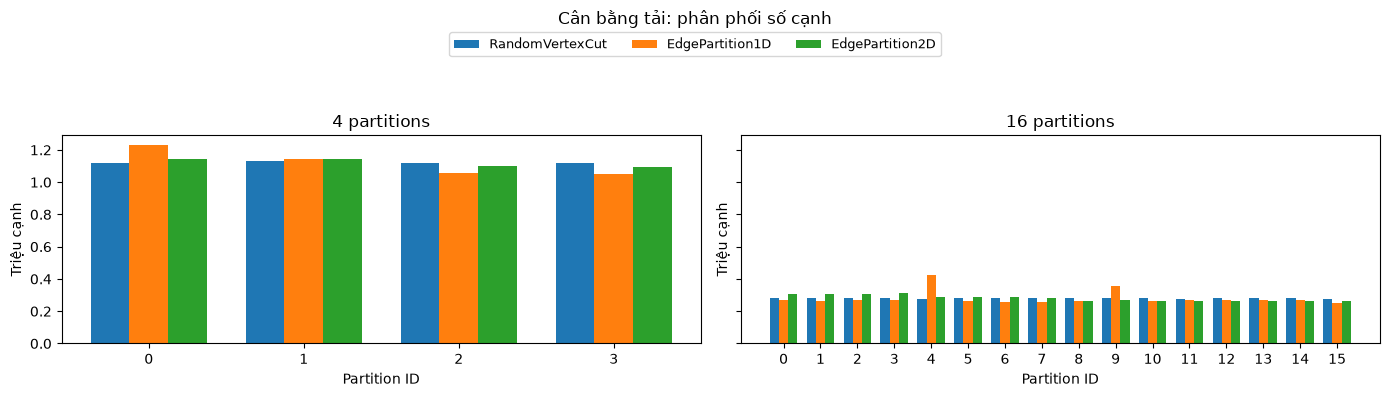

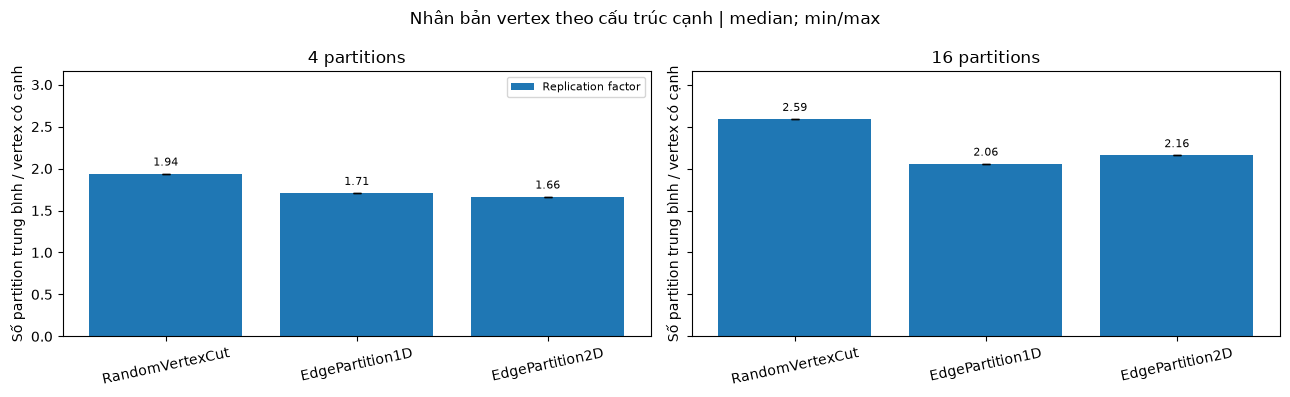

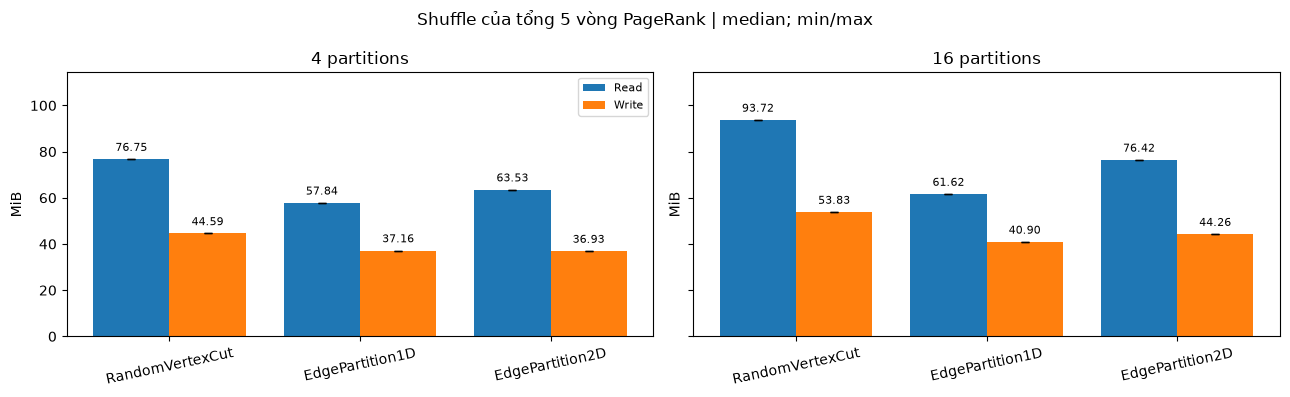

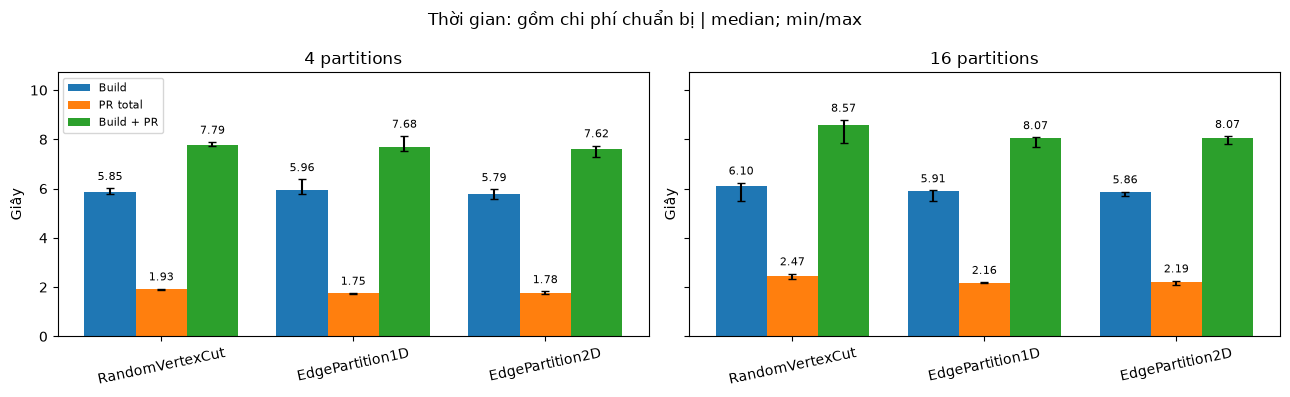


4 partitions:
  Độ lệch tải thấp nhất: RandomVertexCut (1.006)
  Nhân bản thấp nhất: EdgePartition2D (1.663)
  Shuffle read thấp nhất: EdgePartition1D (57.835)
  Tổng thời gian thấp nhất: EdgePartition2D (7.616)
  2D / Random: {'replication_factor': 0.858, 'read_MiB': 0.828, 'total_s': 0.978}

16 partitions:
  Độ lệch tải thấp nhất: RandomVertexCut (1.010)
  Nhân bản thấp nhất: EdgePartition1D (2.056)
  Shuffle read thấp nhất: EdgePartition1D (61.620)
  Tổng thời gian thấp nhất: EdgePartition1D (8.072)
  2D / Random: {'replication_factor': 0.833, 'read_MiB': 0.815, 'total_s': 0.942}

Không suy ra quan hệ nhân quả chỉ từ các chỉ số cùng giảm.
Shuffle là local + remote trên một máy; chưa đo traffic giữa máy.
Cache là giá trị cuối phase lớn nhất; heap/RSS là JVM chung, không phải RAM tối thiểu.


In [13]:
# Biến và output riêng, không thay đổi bảng của phần so sánh framework.
def analyze_partition_strategies():
    part_dir = RUN / "partition_strategies"
    if not part_dir.exists():
        print("Run này chưa có phần partitioning. Chạy phần bổ sung cuối notebook 03.")
        return
    assert (part_dir / "SUCCESS").is_file(), "Phần partitioning chưa hoàn tất."
    print("Partition run:", part_dir)
    config = json.loads((part_dir / "configuration.json").read_text())
    plan = pd.read_csv(part_dir / "schedule.csv")
    checked = pd.read_csv(part_dir / "correctness.csv")
    phases = pd.read_csv(part_dir / "phase_timings.csv")
    metrics = pd.read_csv(part_dir / "phase_task_metrics.csv")
    loads = pd.read_csv(part_dir / "partition_stats.csv")
    strategies = ["RandomVertexCut", "EdgePartition1D", "EdgePartition2D"]
    counts = [4, 16]
    assert config["master"] == "local[2]" and config["iterations"] == 5
    assert len(plan) == 24 and plan.run.is_unique
    assert len(checked) == 24 and checked.passed.all()
    assert set(checked.run) == set(plan.run)
    assert (checked.vertices == config["vertices"]).all()
    assert (checked.max_scaled_error < 1e-9).all()
    assert ((checked.rank_sum - 1).abs() < 1e-9).all()
    for _, group in plan.groupby(["strategy", "partitions"]):
        assert len(group) == 4 and group.warmup.sum() == 1
        assert set(group.repeat) == {-1, 0, 1, 2}
    assert set(plan.strategy) == set(strategies) and set(plan.partitions) == set(counts)
    assert len(phases) == 168
    for run, group in phases.groupby("run"):
        assert group.phase.value_counts().to_dict() == {"pr_iteration": 5, "build": 1, "pr_setup": 1}
        assert set(group[group.phase == "pr_iteration"].iteration) == {1, 2, 3, 4, 5}
    keys = ["run", "phase", "iteration"]
    data = phases.merge(metrics, on=keys, validate="one_to_one")
    assert len(data) == len(phases) == len(metrics)
    assert set(data.run) == set(plan.run)
    assert (data.tasks > 0).all() and (data.failed_tasks == 0).all()
    data = data.merge(plan, on="run", validate="many_to_one")
    data = data[~data.warmup]
    assert not loads.duplicated(["run", "partition_id"]).any()
    assert set(loads.run) == set(plan.run)
    shape_rows = []
    for entry in plan.itertuples(index=False):
        group = loads[loads.run == entry.run]
        assert set(group.partition_id) == set(range(entry.partitions))
        assert group.edges.sum() == config["edges"]
        assert (group.endpoint_vertices <= 2 * group.edges).all()
        assert (group.active_vertices == config["active_vertices"]).all()
        replication = group.endpoint_vertices.sum() / config["active_vertices"]
        imbalance = group.edges.max() / group.edges.mean()
        assert 1 <= replication <= entry.partitions and imbalance >= 1
        shape_rows.append({"run": entry.run, "replication_factor": replication, "load_max_over_mean": imbalance})
    rows = []
    for entry in plan[~plan.warmup].itertuples(index=False):
        group = data[data.run == entry.run]
        elapsed = group.groupby("phase").wall_ms.sum()
        iteration = group[group.phase == "pr_iteration"]
        rows.append({
            "run": entry.run, "strategy": entry.strategy, "partitions": entry.partitions,
            "build_s": elapsed["build"] / 1000,
            "pr_total_s": (elapsed["pr_setup"] + elapsed["pr_iteration"]) / 1000,
            "total_s": elapsed.sum() / 1000,
            "iteration_s": elapsed["pr_iteration"] / 1000,
            "read_MiB": iteration.shuffle_read_bytes.sum() / 1024**2,
            "write_MiB": iteration.shuffle_write_bytes.sum() / 1024**2,
            "gc_ms": group.jvm_gc_ms.sum(),
            "memory_spill_bytes": group.memory_spill_bytes.sum(),
            "disk_spill_bytes": group.disk_spill_bytes.sum(),
            "cache_end_MiB": group.workload_cache_end_bytes.max() / 1024**2,
            "heap_peak_MiB": group.heap_sampled_peak_bytes.max() / 1024**2,
            "rss_peak_MiB": group.rss_sampled_peak_bytes.max() / 1024**2,
        })
    per_run = pd.DataFrame(rows).merge(pd.DataFrame(shape_rows), on="run", validate="one_to_one")
    summary_part = per_run.groupby(["partitions", "strategy"]).median(numeric_only=True)
    ratios_part = summary_part.copy()
    for p in counts:
        baseline = summary_part.loc[(p, "RandomVertexCut")]
        ratios_part.loc[p, :] = summary_part.loc[p].div(baseline).to_numpy()
    destination = part_dir / "analysis"
    destination.mkdir(exist_ok=True)
    per_run.to_csv(destination / "per_run.csv", index=False)
    summary_part.to_csv(destination / "summary.csv")
    ratios_part.to_csv(destination / "ratios_to_random.csv")
    display(summary_part.round(3))
    print("Tỷ lệ so với RandomVertexCut cùng số partition; thấp hơn 1 là giảm:")
    display(ratios_part[["replication_factor", "read_MiB", "pr_total_s", "total_s"]].round(3))
    colors = ["tab:blue", "tab:orange", "tab:green"]

    # Hình 1: cùng trục dọc để so sánh số cạnh tuyệt đối.
    fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
    measured_loads = loads.merge(plan, on="run", validate="many_to_one")
    measured_loads = measured_loads[~measured_loads.warmup]
    for ax, p in zip(axes, counts):
        for i, strategy in enumerate(strategies):
            selected = measured_loads[(measured_loads.partitions == p) & (measured_loads.strategy == strategy)]
            values = selected.groupby("partition_id").edges.median().reindex(range(p))
            ax.bar([x + (i-1)*0.25 for x in range(p)], values / 1e6,
                   width=0.25, color=colors[i], label=strategy)
        ax.set(title=f"{p} partitions", xlabel="Partition ID", ylabel="Triệu cạnh")
        ax.set_xticks(range(p))
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.94), ncol=3, fontsize=9)
    fig.suptitle("Cân bằng tải: phân phối số cạnh")
    fig.tight_layout(rect=(0, 0, 1, 0.84))
    fig.savefig(destination / "partition_load.png", dpi=160)
    plt.show()

    # Hình 2-4: cột median, thanh sai số min/max của 3 lượt.
    for filename, title, columns, labels, ylabel in [
        ("replication", "Nhân bản vertex theo cấu trúc cạnh", ["replication_factor"], ["Replication factor"], "Số partition trung bình / vertex có cạnh"),
        ("shuffle", "Shuffle của tổng 5 vòng PageRank", ["read_MiB", "write_MiB"], ["Read", "Write"], "MiB"),
        ("timing", "Thời gian: gồm chi phí chuẩn bị", ["build_s", "pr_total_s", "total_s"], ["Build", "PR total", "Build + PR"], "Giây"),
    ]:
        fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
        width = 0.8 / len(columns)
        for ax, p in zip(axes, counts):
            for i, (column, label) in enumerate(zip(columns, labels)):
                medians, below, above = [], [], []
                for strategy in strategies:
                    values = per_run[(per_run.partitions == p) & (per_run.strategy == strategy)][column]
                    median = values.median()
                    medians.append(median)
                    below.append(median-values.min())
                    above.append(values.max()-median)
                positions = [x+(i-(len(columns)-1)/2)*width for x in range(3)]
                bars = ax.bar(positions, medians, width=width, yerr=[below, above], capsize=3, label=label)
                ax.bar_label(bars, fmt="%.2f", padding=4, fontsize=8)
            ax.set_xticks(range(3), strategies, rotation=12)
            ax.set(title=f"{p} partitions", ylabel=ylabel)
            ax.margins(y=0.22)
        axes[0].legend(fontsize=8)
        fig.suptitle(title + " | median; min/max")
        fig.tight_layout()
        fig.savefig(destination / (filename + ".png"), dpi=160)
        plt.show()

    # Nhận xét lấy từ run đang đọc, không áp đặt strategy thắng.
    for p in counts:
        current = summary_part.loc[p]
        print(f"\n{p} partitions:")
        for column, label in [("load_max_over_mean","Độ lệch tải thấp nhất"),
                              ("replication_factor","Nhân bản thấp nhất"),
                              ("read_MiB","Shuffle read thấp nhất"),
                              ("total_s","Tổng thời gian thấp nhất")]:
            minimum = current[column].min()
            winners = current.index[current[column] == minimum].tolist()
            print(f"  {label}: {', '.join(winners)} ({minimum:.3f})")
        print("  2D / Random:", ratios_part.loc[(p, "EdgePartition2D"),
              ["replication_factor", "read_MiB", "total_s"]].round(3).to_dict())
    print("\nKhông suy ra quan hệ nhân quả chỉ từ các chỉ số cùng giảm.")
    print("Shuffle là local + remote trên một máy; chưa đo traffic giữa máy.")
    print("Cache là giá trị cuối phase lớn nhất; heap/RSS là JVM chung, không phải RAM tối thiểu.")

analyze_partition_strategies()


### Câu chuyện có thể bảo vệ

Đối chiếu các cấu hình tại cùng số partition trước, rồi mới so ảnh hưởng của tăng số partition.
Ít nhân bản có thể giảm nhu cầu trao đổi thuộc tính, nhưng không bảo đảm tổng shuffle hoặc thời gian thấp hơn.
Shuffle còn phụ thuộc routing, tổng hợp message, checkpoint và cách thực thi thuật toán.
Ở 4 partitions, giới hạn 2√P của 2D bằng P; ở 16 partitions giới hạn này nhỏ hơn P.
Dữ liệu thực tế có thể chưa chạm giới hạn lý thuyết; không mặc định 2D luôn thắng Random.
Nếu 16 partitions chậm hơn dù giảm một chỉ số, xem chi phí tạo thêm task và chuẩn bị trước khi diễn giải.
Kết luận gắn với HI-Small, local[2], cache và checkpoint đang dùng.
Muốn nói về mạng giữa các máy, cần thí nghiệm cluster riêng và remote shuffle theo executor/host.
